Імпорт необхідних бібліотек

In [1]:
import math
import random
import statistics

import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

Функція генерації топології (з ЛР1)

In [2]:
def generate_graph_topology(num_nodes=25, edges_to_remove=5, weight_min=1, weight_max=10, seed=None):
    """Генератор топології з ЛР1; додано параметр seed для відтворюваності експериментів."""
    rng = random.Random(seed)
    G = nx.Graph()

    cols = math.ceil(math.sqrt(num_nodes))
    rows = math.ceil(num_nodes / cols)

    node_count = 0
    for r in range(rows):
        for c in range(cols):
            if node_count >= num_nodes:
                break
            G.add_node((r, c), address=f"10.0.{r}.{c}", pos=(c, -r))
            node_count += 1

    for r in range(rows):
        for c in range(cols):
            if not G.has_node((r, c)):
                continue
            if G.has_node((r, c + 1)):
                G.add_edge((r, c), (r, c + 1), weight=rng.randint(weight_min, weight_max))
            if G.has_node((r + 1, c)):
                G.add_edge((r, c), (r + 1, c), weight=rng.randint(weight_min, weight_max))

    removed_count, attempts = 0, 0
    while removed_count < edges_to_remove and attempts < 1000:
        edges = list(G.edges())
        if not edges:
            break
        u, v = rng.choice(edges)
        weight = G[u][v]['weight']
        G.remove_edge(u, v)
        if nx.is_connected(G):
            removed_count += 1
        else:
            G.add_edge(u, v, weight=weight)
        attempts += 1

    if removed_count < edges_to_remove:
        print(f"Увага: вдалося видалити лише {removed_count} ребер без втрати зв'язності.")
    return G

Середовище: площина даних мережі (вузли лише пересилають пакети та повідомляють контролеру про невідомий потік)

In [3]:
# Інтерфейси вузла: північ, схід, південь, захід (зміщення рядка та стовпця в сітці)
DIRECTIONS = {'N': (-1, 0), 'E': (0, 1), 'S': (1, 0), 'W': (0, -1)}


class DataPlane:
    """Площина даних (середовище): вузли лише пересилають пакети за встановленими правилами.
    Усі рішення приймає контролер, а граф G доступний лише цьому класу."""

    def __init__(self, G, src_addr, dst_addr):
        self.G = G
        self._node = {d['address']: n for n, d in G.nodes(data=True)}
        for addr in (src_addr, dst_addr):
            if addr not in self._node:
                raise ValueError(f"Адреси {addr} немає в мережі")
        self.head = src_addr   # вузол, на якому закінчується встановлена частина шляху
        self.rules = []        # встановлені правила: (вузол, інтерфейс)

    def packet_in(self):
        """Подія «невідомий потік»: голова потоку надсилає контролеру свою таблицю каналів
        у вигляді {інтерфейс: (адреса сусіда, затримка каналу)}."""
        node = self._node[self.head]
        links = {}
        for d, (dr, dc) in DIRECTIONS.items():
            nb = (node[0] + dr, node[1] + dc)
            if self.G.has_edge(node, nb):
                links[d] = (self.G.nodes[nb]['address'], self.G[node][nb]['weight'])
        return self.head, links

    def install_rule(self, direction):
        """Дія 1: встановити правило через інтерфейс; голова переходить на сусіда."""
        head, links = self.packet_in()
        if direction not in links:
            raise ValueError(f"Вузол {head} не має каналу {direction}")
        self.rules.append((head, direction))
        self.head = links[direction][0]

    def revoke_last_rule(self):
        """Дія 2: відкликати останнє правило; голова повертається на попередній вузол."""
        node_addr, _ = self.rules.pop()
        self.head = node_addr

Агент: мережевий контролер з обмеженою видимістю

In [4]:
class SDNController:
    """Раціональний агент-контролер з обмеженою видимістю (оперативний пошук у глибину
    з жадібною евристикою та відкликанням правил у тупиках).

    alpha - вага евристичної оцінки відстані до отримувача відносно затримки каналу."""

    def __init__(self, src, dst, alpha=1.0):
        self.src, self.dst, self.alpha = src, dst, alpha
        self.dst_xy = self._xy(dst)   # координати отримувача з адреси 10.0.<рядок>.<стовпець>
        self.links = {}               # карта: {вузол_a, вузол_b} -> затримка (побачені канали)
        self.visited = set()          # вузли, з яких уже надходила телеметрія
        self.dead = set()             # вузли-тупики (правило до них відкликано)
        self.path = [src]             # вузли встановленого шляху
        self.rules = []               # встановлені правила (вузол, інтерфейс)
        self.installed = 0            # лічильники накладних витрат площини керування
        self.revoked = 0
        self.log, self.frames = [], []

    @staticmethod
    def _xy(addr):
        _, _, r, c = addr.split('.')
        return int(r), int(c)

    def _manhattan(self, addr):
        r, c = self._xy(addr)
        return abs(r - self.dst_xy[0]) + abs(c - self.dst_xy[1])

    def _perceive(self, head, links):
        """Оновлення карти за телеметрією голови потоку."""
        self.visited.add(head)
        for nb, w in links.values():
            self.links[frozenset((head, nb))] = w

    def _choose(self, links):
        """Серед ще не відвіданих сусідів обирає мінімум оцінки: затримка каналу +
        alpha * (середня відома затримка) * (манхеттенська відстань сусіда до отримувача)."""
        avg = sum(self.links.values()) / len(self.links)
        best = None
        for d, (nb, w) in links.items():
            if nb in self.visited:
                continue
            key = (w + self.alpha * avg * self._manhattan(nb), w)
            if best is None or key < best[0]:
                best = (key, d, nb, w)
        return best

    @property
    def delay(self):
        """Показник ефективності: сумарна затримка встановленого шляху."""
        return sum(self.links[frozenset(p)] for p in zip(self.path, self.path[1:]))

    def run(self, dp, verbose=False, max_steps=10_000):
        """Цикл: packet_in -> оновлення карти -> дія (встановити / відкликати / завершити)."""
        for step in range(1, max_steps + 1):
            head, links = dp.packet_in()
            self._perceive(head, links)
            done, ok = False, True

            if head == self.dst:
                text, short = "отримувача досягнуто, завершити шлях", "завершення"
                done = True
            else:
                choice = self._choose(links)
                if choice is not None:
                    _, d, nb, w = choice
                    dp.install_rule(d)
                    self.rules.append((head, d))
                    self.path.append(nb)
                    self.installed += 1
                    text = f"встановити правило {d}: {head} → {nb} (затримка {w})"
                    short = f"встановити {d}"
                elif self.rules:
                    self.dead.add(head)
                    prev, d = self.rules.pop()
                    self.path.pop()
                    dp.revoke_last_rule()
                    self.revoked += 1
                    text = f"тупик, відкликати правило {d} на вузлі {prev}"
                    short = "відкликати правило"
                else:
                    text, short = "відкликати нічого, шляху не існує", "невдача"
                    done, ok = True, False

            seen = ", ".join(f"{d}→{nb} ({w})" for d, (nb, w) in links.items())
            line = f"Крок {step:2d} | голова {head} | канали: {seen} | дія: {text}"
            self.log.append(line)
            if verbose:
                print(line)
            self.frames.append(dict(step=step, head=dp.head, path=list(self.path),
                                    known=set(self.links), dead=set(self.dead), short=short))
            if done:
                return ok
        return False

    def summary(self):
        return dict(nodes=len(self.path), delay=self.delay,
                    installed=self.installed, revoked=self.revoked)

Візуалізація стану мережі після дій контролера

In [5]:
LEGEND = [
    Line2D([], [], marker='o', ls='', markerfacecolor='lightgreen', markeredgecolor='dimgray', markersize=12, label='відправник'),
    Line2D([], [], marker='o', ls='', markerfacecolor='gold', markeredgecolor='dimgray', markersize=12, label='отримувач'),
    Line2D([], [], marker='o', ls='', markerfacecolor='orange', markeredgecolor='dimgray', markersize=12, label='вузол із правилом'),
    Line2D([], [], marker='o', ls='', markerfacecolor='lightgray', markeredgecolor='dimgray', markersize=12, label='тупик (правило відкликано)'),
    Line2D([], [], marker='o', ls='', markerfacecolor='lightblue', markeredgecolor='dimgray', markersize=12, label='відомий, ще не відвіданий'),
    Line2D([], [], marker='o', ls='', markerfacecolor='white', markeredgecolor='dimgray', markersize=12, label='невідомий вузол'),
    Line2D([], [], marker='o', ls='', markerfacecolor='white', markeredgecolor='red', markeredgewidth=3, markersize=12, label='голова потоку'),
    Line2D([], [], color='red', lw=4, label='встановлений шлях'),
]


def draw_state(G, frame, src, dst, ax=None, short=False, title=None):
    """Малює стан мережі після дії контролера: що встановлено, що відомо контролеру, де голова потоку."""
    a2n = {d['address']: n for n, d in G.nodes(data=True)}
    pos = nx.get_node_attributes(G, 'pos')
    standalone = ax is None
    if standalone:
        _, ax = plt.subplots(figsize=(10, 8))

    path = [a2n[a] for a in frame['path']]
    path_edges = list(zip(path, path[1:]))
    known_edges = [tuple(a2n[a] for a in e) for e in frame['known']]
    known_nodes = {n for e in known_edges for n in e}
    dead = {a2n[a] for a in frame['dead']}
    head = a2n[frame['head']]

    fill, border, width = [], [], []
    for n in G.nodes:
        if n == a2n[dst]:
            fill.append('gold')
        elif n == a2n[src]:
            fill.append('lightgreen')
        elif n in path:
            fill.append('orange')
        elif n in dead:
            fill.append('lightgray')
        elif n in known_nodes:
            fill.append('lightblue')
        else:
            fill.append('white')
        border.append('red' if n == head else 'dimgray')
        width.append(3.5 if n == head else 1)

    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#dddddd', style='dashed', width=1)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=known_edges, edge_color='gray', width=1.5)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=path_edges, edge_color='red', width=4)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=fill, edgecolors=border,
                           linewidths=width, node_size=1100 if short else 2600)
    labels = {n: (G.nodes[n]['address'].split('.', 2)[2] if short else G.nodes[n]['address'])
              for n in G.nodes}
    nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_size=8 if short else 9, font_weight='bold')
    nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels={e: G[e[0]][e[1]]['weight'] for e in known_edges},
                                 font_color='darkred', font_size=8 if short else 10)
    ax.set_title(title or f"Крок {frame['step']}: {frame['short']}", fontsize=10 if short else 14)
    ax.axis('off')
    if standalone:
        ax.legend(handles=LEGEND, loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=4, frameon=False)
        plt.show()


def show_frames(G, frames, src, dst, max_frames=8, cols=4):
    """Стан мережі після послідовних дій контролера (рівномірна вибірка з max_frames кадрів)."""
    n = len(frames)
    idx = list(range(n)) if n <= max_frames else \
        sorted({round(i * (n - 1) / (max_frames - 1)) for i in range(max_frames)})
    rows = math.ceil(len(idx) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4.6 * rows))
    axes = list(axes.flat) if hasattr(axes, 'flat') else [axes]
    for ax, i in zip(axes, idx):
        draw_state(G, frames[i], src, dst, ax=ax, short=True)
    for ax in axes[len(idx):]:
        ax.axis('off')
    fig.legend(handles=LEGEND, loc='lower center', ncol=4, frameon=False)
    plt.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()

Виконання (Main): встановлення шляху, журнал дій та підсумкові показники

In [6]:
# Адреси відправника та отримувача задаються при старті програми
SRC_ADDR = "10.0.0.0"
DST_ADDR = "10.0.4.4"

G = generate_graph_topology(num_nodes=25, edges_to_remove=8, weight_min=1, weight_max=10, seed=9)
dataplane = DataPlane(G, SRC_ADDR, DST_ADDR)
controller = SDNController(SRC_ADDR, DST_ADDR)

success = controller.run(dataplane, verbose=True)

res = controller.summary()
print()
print("Шлях:", " → ".join(controller.path))
print(f"Кількість вузлів у шляху: {res['nodes']}")
print(f"Сумарна затримка шляху: {res['delay']}")
print(f"Встановлено правил: {res['installed']}, відкликано: {res['revoked']} "
      f"(накладні витрати площини керування: {res['installed'] + res['revoked']})")

Крок  1 | голова 10.0.0.0 | канали: S→10.0.1.0 (10) | дія: встановити правило S: 10.0.0.0 → 10.0.1.0 (затримка 10)
Крок  2 | голова 10.0.1.0 | канали: N→10.0.0.0 (10), E→10.0.1.1 (8), S→10.0.2.0 (10) | дія: встановити правило E: 10.0.1.0 → 10.0.1.1 (затримка 8)
Крок  3 | голова 10.0.1.1 | канали: N→10.0.0.1 (5), E→10.0.1.2 (2), S→10.0.2.1 (6), W→10.0.1.0 (8) | дія: встановити правило E: 10.0.1.1 → 10.0.1.2 (затримка 2)
Крок  4 | голова 10.0.1.2 | канали: S→10.0.2.2 (10), W→10.0.1.1 (2) | дія: встановити правило S: 10.0.1.2 → 10.0.2.2 (затримка 10)
Крок  5 | голова 10.0.2.2 | канали: N→10.0.1.2 (10), E→10.0.2.3 (4), S→10.0.3.2 (1), W→10.0.2.1 (3) | дія: встановити правило S: 10.0.2.2 → 10.0.3.2 (затримка 1)
Крок  6 | голова 10.0.3.2 | канали: N→10.0.2.2 (1), E→10.0.3.3 (5), S→10.0.4.2 (4) | дія: встановити правило S: 10.0.3.2 → 10.0.4.2 (затримка 4)
Крок  7 | голова 10.0.4.2 | канали: N→10.0.3.2 (4), W→10.0.4.1 (4) | дія: встановити правило W: 10.0.4.2 → 10.0.4.1 (затримка 4)
Крок  8 | 

Стан мережі після послідовних дій контролера

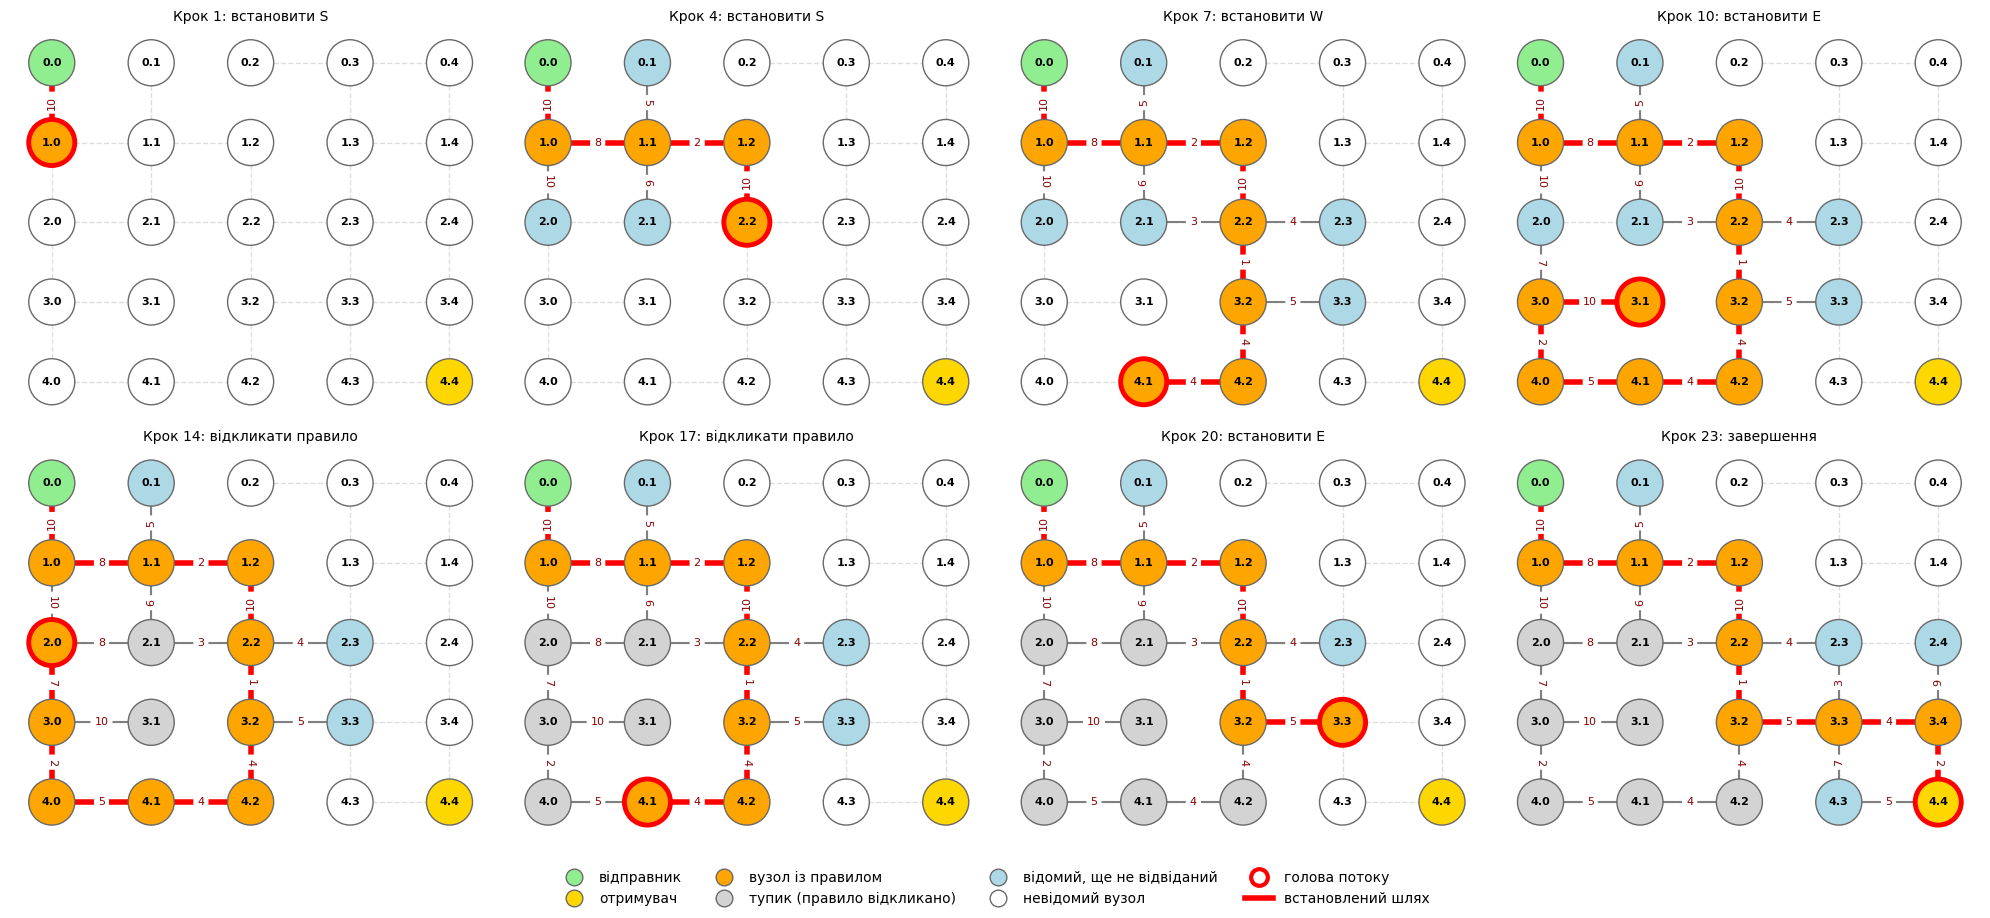

In [7]:
show_frames(G, controller.frames, SRC_ADDR, DST_ADDR, max_frames=8, cols=4)

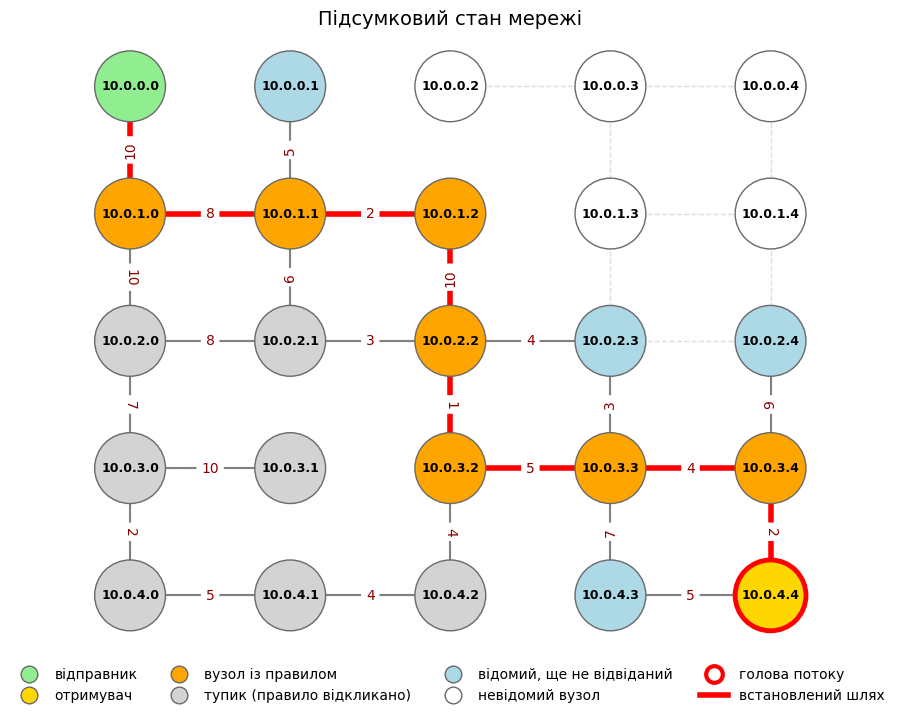

In [8]:
draw_state(G, controller.frames[-1], SRC_ADDR, DST_ADDR, title="Підсумковий стан мережі")

Додаткове завдання: порівняння шляху контролера з оптимальним шляхом за алгоритмом Дейкстри (повна топологія)

In [9]:
def compare(seeds, src, dst, num_nodes=25, edges_to_remove=8):
    """Запускає контролер і алгоритм Дейкстри (з повною топологією) на згенерованих топологіях."""
    rows = []
    for seed in seeds:
        G = generate_graph_topology(num_nodes, edges_to_remove, 1, 10, seed=seed)
        dp = DataPlane(G, src, dst)
        ctrl = SDNController(src, dst)
        ctrl.run(dp)
        n_src = next(n for n, d in G.nodes(data=True) if d['address'] == src)
        n_dst = next(n for n, d in G.nodes(data=True) if d['address'] == dst)
        opt_path = nx.dijkstra_path(G, n_src, n_dst, weight='weight')
        opt_delay = nx.dijkstra_path_length(G, n_src, n_dst, weight='weight')
        s = ctrl.summary()
        rows.append(dict(seed=seed, ctrl_delay=s['delay'], opt_delay=opt_delay,
                         ctrl_nodes=s['nodes'], opt_nodes=len(opt_path),
                         installed=s['installed'], revoked=s['revoked']))
    return rows


rows = compare([1, 2, 3, 4, 5, 9], SRC_ADDR, DST_ADDR)

print(f"{'Топологія':>9} | {'Затримка контролера':>19} | {'Затримка оптимуму':>17} | "
      f"{'Надлишок':>8} | {'Вузлів (контр./опт.)':>20} | {'Встановлено':>11} | {'Відкликано':>10}")
for r in rows:
    excess = (r['ctrl_delay'] / r['opt_delay'] - 1) * 100
    print(f"{'seed=' + str(r['seed']):>9} | {r['ctrl_delay']:>19} | {r['opt_delay']:>17} | "
          f"{excess:>7.1f}% | {str(r['ctrl_nodes']) + ' / ' + str(r['opt_nodes']):>20} | "
          f"{r['installed']:>11} | {r['revoked']:>10}")

Топологія | Затримка контролера | Затримка оптимуму | Надлишок | Вузлів (контр./опт.) | Встановлено | Відкликано
   seed=1 |                  47 |                38 |    23.7% |                9 / 9 |           8 |          0
   seed=2 |                  34 |                24 |    41.7% |                9 / 9 |           8 |          0
   seed=3 |                  40 |                40 |     0.0% |                9 / 9 |           8 |          0
   seed=4 |                  56 |                38 |    47.4% |              13 / 11 |          12 |          0
   seed=5 |                  40 |                40 |     0.0% |                9 / 9 |          12 |          4
   seed=9 |                  42 |                39 |     7.7% |                9 / 9 |          15 |          7


Вибір евристики: вплив коефіцієнта alpha на якість шляху (300 топологій). alpha = 0 означає, що контролер дивиться лише на затримку каналу

In [10]:
def evaluate(alpha, seeds):
    ratios, revoked, optimal = [], [], 0
    for seed in seeds:
        G = generate_graph_topology(25, 8, 1, 10, seed=seed)
        dp = DataPlane(G, SRC_ADDR, DST_ADDR)
        ctrl = SDNController(SRC_ADDR, DST_ADDR, alpha=alpha)
        ctrl.run(dp)
        opt = nx.dijkstra_path_length(G, (0, 0), (4, 4), weight='weight')
        ratios.append(ctrl.delay / opt)
        revoked.append(ctrl.revoked)
        optimal += ctrl.delay == opt
    return statistics.mean(ratios), statistics.mean(revoked), optimal / len(seeds)


seeds = range(1000, 1300)   # 300 різних топологій
print(f"{'alpha':>5} | {'Середнє відношення затримок':>27} | {'Середнє відкликань':>18} | {'Частка оптимальних':>18}")
for alpha in (0, 0.25, 0.5, 1):
    ratio, rev, share = evaluate(alpha, seeds)
    print(f"{alpha:>5} | {ratio:>27.3f} | {rev:>18.2f} | {share:>17.0%}")

alpha | Середнє відношення затримок | Середнє відкликань | Частка оптимальних


    0 |                       1.487 |               4.68 |               18%


 0.25 |                       1.276 |               3.00 |               30%


  0.5 |                       1.199 |               1.82 |               34%
    1 |                       1.178 |               1.25 |               37%
